In [1]:
import pandas as pd
import re
import os #pour naviguer dans les dossiers
from io import StringIO
import s3fs #pour connecter au bucket

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


from sklearn.datasets import load_digits



In [2]:
import random

from functools import partial
import math

import tqdm
import sklearn

from sklearn import metrics
from sklearn.neighbors import NearestNeighbors

    

In [3]:
import networkx as nx
import networkx.algorithms.community as nx_comm
from ipysigma import Sigma
#import community as community_louvain
import matplotlib.cm as cm


In [4]:


# Create filesystem object
S3_ENDPOINT_URL = "https://" + os.environ["AWS_S3_ENDPOINT"]
fs = s3fs.S3FileSystem(client_kwargs={'endpoint_url': S3_ENDPOINT_URL})

BUCKET_OUT = "aluneau"

last_file="anonymous_answer_2026-07-24.csv"


In [25]:
with fs.open(f"{BUCKET_OUT}/data_eP8/raw/{last_file}", "r") as file_in:
    df0 = pd.read_csv(file_in, sep =",")

list_affil = pd.read_csv("list_affiliation.csv", sep =",")
df01 = df0.loc[~df0.q45_clé.isin(["H5X6-KL2Z",'PS8W-TJ9P'])].drop_duplicates(subset="q45_clé")#.merge(list_affil, on = ["q45_clé", "q44_ufr_labo"], how = "left")
df01


,qno_obs,q1_so_principles,q2_hal_depot,q3_octavi_depot,q4_diff_data,q4_autres_entrepots,q5_r,q5_python,q5_excel,q5_julia,...,labo,ufr,departement,ecole_doc,partition_1,label_recherche_1,auto_lab_research_cluster,research_fields,clust_type_data,auto_clust_data
1,2,"Oui, un peu","Oui, une fois",Non,Non,NaN,Non,Non,Non,Non,...,NaN,NaN,NaN,NaN,4.0,Etudes sociales des arts et de la culture,"[""SH4 L'esprit humain et sa complexité"", 'SH8 ...","['SH3', 'SH4', 'SH5', 'SH6']",Corpus textuels,"['Données textuelles ou documentaires', 'Métad..."
2,3,"Oui, tout à fait","Oui, plusieurs fois",Je ne connais pas Octaviana,Non,NaN,Non,Non,Oui,Non,...,paragraphe,psychologie,NaN,NaN,5.0,Psychologie,"[""SH4 L'esprit humain et sa complexité"", 'LS5 ...",['SH4'],Entretiens,"['Données textuelles ou documentaires', 'Autre..."
3,4,"Oui, un peu","Oui, une fois",Non,"Autre, précisez",OSF,Oui,Non,Non,Non,...,sfl,sdl,NaN,NaN,5.0,Psychologie,"[""SH4 L'esprit humain et sa complexité"", 'LS5 ...",['SH4'],Etudes expérimentale,"[""Données expérimentales ou d'observation"", ""D..."
4,5,"Oui, un peu","Oui, systématiquement",Non,Non,NaN,Non,Non,Oui,Non,...,NaN,NaN,NaN,NaN,3.0,Histoires de l'art et des sciences,"['SH8 Études des cultures et des arts', ""SH6 L...","['SH1', 'SH3', 'SH6', 'SH8']",Données du web et statistiques,"['Données statistiques', 'Données du web', 'Do..."
5,6,"Oui, un peu","Oui, systématiquement",Non;Je ne connais pas Octaviana,Non,NaN,Oui,Non,Oui,Non,...,dysco,psychologie,NaN,NaN,5.0,Psychologie,"[""SH4 L'esprit humain et sa complexité"", 'LS5 ...","['LS4', 'LS5']",Données statistiques et observations,"['Données statistiques', ""Données expérimental..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
114,117,"Oui, un peu","Oui, plusieurs fois",Non,"Autre, précisez",OSF,Oui,Oui,Oui,Non,...,dysco,NaN,NaN,NaN,5.0,Psychologie,"[""SH4 L'esprit humain et sa complexité"", 'LS5 ...","['SH4', 'LS5']",Données statistiques et observations,"['Données statistiques', ""Données expérimental..."
115,118,"Oui, un peu","Oui, systématiquement",Non,Non,NaN,Oui,Non,Oui,Non,...,liage,sepf,sciences de l'education,NaN,0.0,"Individus, normes, sociétés","['SH2 Institutions, gouvernance et systèmes ju...","['SH2', 'SH3', 'SH7']",Données du web et statistiques,"['Données statistiques', 'Données du web', 'Do..."
116,119,"Oui, un peu","Oui, plusieurs fois",Non,Non,NaN,Oui,Non,Oui,Non,...,ladyss,erites,géographie,NaN,0.0,"Individus, normes, sociétés","['SH2 Institutions, gouvernance et systèmes ju...","['SH1', 'SH2', 'SH3', 'SH7']",Données statistiques et textutelles,"['Données statistiques', 'Données textuelles o..."
117,120,Non,"Oui, plusieurs fois",Non;Je ne connais pas Octaviana,"Autre, précisez",Mendeley data,Non,Oui,Oui,Non,...,NaN,NaN,NaN,NaN,10.0,Sciences informatiques,"['PE6 Sciences informatiques et informatique',...","['PE1', 'PE6', 'PE8', 'PE11']",Données du web et statistiques,"['Données statistiques', 'Données du web', 'Do..."


In [26]:

df_col = pd.read_csv("../le_questionnaire/dico_variable.csv", sep = ",")


# Profil disciplinaire

In [27]:
def split_multiple_choices(data, column, index, sep = '|'):
    """
    split and explode column with multiple value

    data = a panda dataframe
    column = name of column which we want to split.
    index = column corresponding to id of rows
    sep = by default '|'. Character use to separate values.
    """
    df_split = data.copy()
    df_split[column] = df_split[column].str.split(sep)
    df_explode = df_split.explode(column)
    gb_data = df_explode.groupby([column]).agg(nb = (index, "size")).reset_index()
    gb_data["total"] = data[index].nunique()
    gb_data["freq"] = gb_data.nb/gb_data.total*100
    gb_data["total_freq"] = gb_data.total/gb_data.total*100

    return gb_data, df_explode

In [28]:
gb_data, df_exp = split_multiple_choices(df0, column='q10_type_data', index = "q45_clé", sep = ';')
gb_data1, df_exp1 = split_multiple_choices(df0, column='q24_research_fields', index = "q45_clé", sep = ';')


In [29]:
df_rf = df_exp[["q45_clé", 'q24_research_fields']].copy()
df_rf["value"] = 1
df_rf.loc[df_rf.q45_clé=="82N2-HDNU"]

,q45_clé,q24_research_fields,value
107,82N2-HDNU,"SH1 Individus, marchés et organisations;SH5 Te...",1
107,82N2-HDNU,"SH1 Individus, marchés et organisations;SH5 Te...",1
107,82N2-HDNU,"SH1 Individus, marchés et organisations;SH5 Te...",1


In [30]:
df_d = df_exp[["q45_clé", 'q10_type_data']].copy()
df_d["value"] = 1

In [31]:
df_df=pd.concat([df_rf.rename(columns={"q24_research_fields":"variable"}), df_d.rename(columns={"q10_type_data":"variable"},)])
df_df

,q45_clé,variable,value
0,PS8W-TJ9P,"SH1 Individus, marchés et organisations;SH2 In...",1
0,PS8W-TJ9P,"SH1 Individus, marchés et organisations;SH2 In...",1
0,PS8W-TJ9P,"SH1 Individus, marchés et organisations;SH2 In...",1
0,PS8W-TJ9P,"SH1 Individus, marchés et organisations;SH2 In...",1
1,GNEG-5QXQ,SH3 Le monde social et ses interactions;SH4 L'...,1
...,...,...,...
117,32TW-JLY5,Données du web,1
117,32TW-JLY5,Données statistiques,1
117,32TW-JLY5,Données multimédia,1
118,6GVE-N5NJ,Données expérimentales ou d'observation,1


In [32]:
def create_term_term_matrix(data, what, list_columns, value):
    table = pd.pivot_table(data, 
                           values=value, index=what, columns=list_columns, aggfunc=np.sum, fill_value=0)
    
    term_term = np.dot(table, table.T) # multiplication de la transposé de
    return term_term, table

## Calcule du cosine

In [33]:
def find_k_neighbor(mi_matrix, precompute, kneighbor):
    mi_array = np.array(mi_matrix)
    
    if precompute == True:
        m =scipy.sparse.csc_matrix(mi_array)
        dist=metrics.pairwise.cosine_distances(m)
        list_voisin = []
        list_voisin_dist =[]
        samples = dist, x
        neigh = NearestNeighbors(n_neighbors=kneighbor, metric='precomputed')
        neigh.fit(samples)
        for x in range(len(dist)):
            voisins = neigh.kneighbors(dist[[x]], return_distance=True)
            voisins_dist = voisins[0].tolist()
            voisins_id = voisins[1].tolist()
            #print(voisins_id)
            list_voisin.append(voisins_id[0])
            list_voisin_dist.append(voisins_dist[0])
    else:
        list_voisin = []
        list_voisin_dist =[]
        samples = mi_array
        neigh = NearestNeighbors(n_neighbors=kneighbor, metric='cosine')
        neigh.fit(samples)
        for x in range(len(mi_array)):
            voisins = neigh.kneighbors(mi_array[[x]], return_distance=True)
            voisins_dist = voisins[0].tolist()
            voisins_id = voisins[1].tolist()
            #print(voisins_id)
            list_voisin.append(voisins_id[0])
            list_voisin_dist.append(voisins_dist[0])
    return list_voisin, list_voisin_dist
    
    
        

In [34]:
def matrix_to_df(list_voisin, list_voisin_dist, table):
    df_dist0 = pd.DataFrame(list_voisin_dist)
    df_dist0["term_x"] = table.index
    df_dist0["id_x"] = df_dist0.index
    dict_id = dict(zip(df_dist0[["id_x","term_x"]].id_x.drop_duplicates(), df_dist0[["id_x","term_x"]].term_x.drop_duplicates()))
    
    df_dist = pd.melt(df_dist0, id_vars=["term_x","id_x"], value_vars= df_dist0.columns[0:-2], value_name="distance")
    #df_dist["term_y"] = df_dist.id_y.map(dict_id.get)
    
    
    df_voisin0 = pd.DataFrame(list_voisin)
    df_voisin0["term_x"] = table.index
    df_voisin0["id_x"] = df_voisin0.index
    dict_id = dict(zip(df_voisin0[["id_x","term_x"]].id_x.drop_duplicates(), df_voisin0[["id_x","term_x"]].term_x.drop_duplicates()))
    
    df_voisin = pd.melt(df_voisin0, id_vars=["term_x","id_x"], value_vars= df_voisin0.columns[0:-2], value_name="id_y")
    df_voisin["term_y"] = df_voisin.id_y.map(dict_id.get)
    df_voisin = df_voisin.merge(df_dist[["term_x","variable","distance"]], on =["term_x","variable"], how ="left")
    df_voisin.loc[df_voisin.term_x=="2DRU-P3AV"]
    
    
    return df_voisin

In [35]:
term_term, table = create_term_term_matrix(data = df_df,  what ="q45_clé", list_columns=["variable"], value="value")
list_voisin, list_voisin_dist = find_k_neighbor(mi_matrix=term_term, precompute=False, kneighbor=5)

/tmp/ipykernel_2506/4206556320.py:2: FutureWarning: The provided callable <function sum at 0x7f317826f6a0> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  table = pd.pivot_table(data,


In [36]:
df_voisin = matrix_to_df(list_voisin, list_voisin_dist, table)
df_voisin

,term_x,id_x,variable,id_y,term_y,distance
0,2DRU-P3AV,0,0,0,2DRU-P3AV,0.000000e+00
1,2JQN-P9PA,1,0,1,2JQN-P9PA,0.000000e+00
2,2QNC-8AAQ,2,0,2,2QNC-8AAQ,1.110223e-16
3,2Y89-7BR9,3,0,3,2Y89-7BR9,0.000000e+00
4,32TW-JLY5,4,0,4,32TW-JLY5,0.000000e+00
...,...,...,...,...,...,...
590,YL4Q-KQAK,114,4,2,2QNC-8AAQ,3.355901e-01
591,YTMC-B4DP,115,4,27,9K9T-RVNL,1.218660e-02
592,ZB5S-ABHN,116,4,52,GLRV-TMM9,2.392536e-01
593,ZBFK-V8BA,117,4,89,QYE4-8EYZ,2.457524e-01


In [37]:
#df_voisin.to_csv(f"{path}/analyse_periods/5_plus_proche_voisins_periode_0_fb.csv", sep =",")

In [38]:
df_voisin0 = df_voisin[["term_x", "term_y", "distance"]].loc[df_voisin["distance"]<= 0.8]


<Axes: >

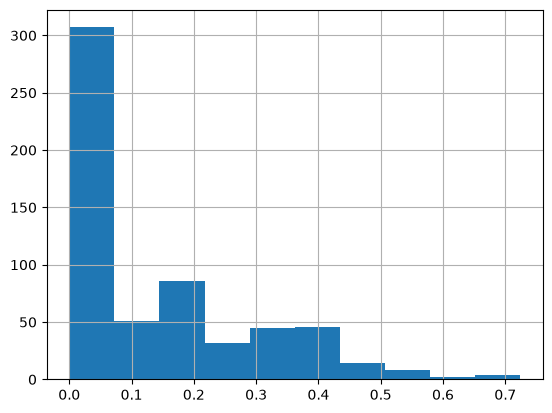

In [39]:
df_voisin0.distance.hist()

In [40]:
G = nx.from_pandas_edgelist(df_voisin, 'term_x', 'term_y', ['distance'])
nodes = df_voisin[["term_x"]].rename(columns={"term_x":"q45_clé"}).drop_duplicates().merge(df01[["q45_clé","labo","ufr","departement","clust_type_data","research_fields","label_recherche_1"]], on=["q45_clé"], how="left")
nodes

,q45_clé,labo,ufr,departement,clust_type_data,research_fields,label_recherche_1
0,2DRU-P3AV,paragraphe,mitsic,informatique,Données du web et statistiques,"['SH4', 'PE6']",Psychologie
1,2JQN-P9PA,NaN,NaN,NaN,Etudes expérimentale,['SH4'],Psychologie
2,2QNC-8AAQ,NaN,NaN,NaN,Entretiens,"['SH1', 'SH3', 'SH5', 'SH7']","Individus, normes, sociétés"
3,2Y89-7BR9,transcrit,llce lea,NaN,Entretiens,"['SH4', 'SH5']",Psychologie
4,32TW-JLY5,NaN,NaN,NaN,Données du web et statistiques,"['PE1', 'PE6', 'PE8', 'PE11']",Sciences informatiques
...,...,...,...,...,...,...,...
114,YL4Q-KQAK,NaN,NaN,NaN,Données statistiques et textutelles,"['SH1', 'SH3', 'SH8']",Histoires de l'art et des sciences
115,YTMC-B4DP,paragraphe,NaN,ied,Données statistiques et observations,"['SH3', 'SH4']",Psychologie sociale
116,ZB5S-ABHN,NaN,le,NaN,Données statistiques et observations,"['SH4', 'SH5']",Psychologie
117,ZBFK-V8BA,NaN,NaN,NaN,Données statistiques et observations,['PE6'],Sciences informatiques


In [41]:
#first compute the best partition
partition_1 = nx.community.louvain_communities(G, seed=111, resolution=1)
partition_2 = nx.community.louvain_communities(G, seed=111, resolution=2)
len(partition_1)

12

In [42]:
dict_partition_1 = {}
dict_partition_2 = {}

for n, part in enumerate(partition_1):
    for key in part:
        dict_partition_1[key] = n


for n, part in enumerate(partition_2):
    for key in part:
        dict_partition_2[key] = n

nodes["Label"] = nodes.q45_clé
nodes["partition_1"]= nodes.q45_clé.map(dict_partition_1.get)
nodes["partition_2"]= nodes.q45_clé.map(dict_partition_2.get)
node_attr = nodes.set_index('q45_clé').to_dict('index')
nx.set_node_attributes(G, node_attr)


In [44]:
Sigma(G, node_size = G.degree, node_color = partition_1)

Sigma(nx.Graph with 119 nodes and 474 edges)

In [ ]:
df = pd.read_csv("../script_traitement/buparis8_chercheurs_besoins_accompagnement_7-24-2026_9_54.csv", sep =";")
df[["146. Clé", "143. Prénom", "142. Nom"]].loc[df["146. Clé"]=="82N2-HDNU"]

In [ ]:
for x in df["28. type_data"].loc[df["142. Nom"].isin(["Rieucau"])]:
    print(x)

In [ ]:
df_rf.loc[df_rf.q45_clé=="N99W-FKD9"]

## Labellisation "automatique" basée sur une forme e TF-IDF

$\text{TFIDF} = \text{TF} \times \text{IDF}$


$\text{TF} = \frac{\text{number of time term T appears in document D}}{\text{Total numbers of terms in document d}}$


$\text{IDF} = \frac{\text{Total number of documents D in corpus}}{\text{Numbers of documents containing term T}}$

$\text{TF} = \frac{\text{nOmbre de fois que le champ F de recherche apparaît dans le cluster C}}{\text{Nombre total de champs dans le cluster C}}$


$\text{IDF} = \frac{\text{Nombre total de cluster}}{\text{Nombre de cluster contenant le champ F}}$

In [ ]:
df_rf["cluster"] = df_rf.q45_clé.map(dict_partition_1)
dict_spec_fields = {}
i=-1
for c in df_rf.cluster.unique():
    i+=1
    cl = df_rf.loc[df_rf.cluster==c]
    #print("####\n", len(cl))
    list_field_cluster = []
    for field in cl.q10_type_data.unique():
        champ_in_cl = len(cl.loc[cl.q10_type_data==field])
        
        cl_with_field = df_rf.loc[df_rf.q10_type_data==field].cluster.nunique()
        tf = champ_in_cl/len(cl)
        idf= np.log(df_rf.cluster.nunique()/cl_with_field)
        list_field_cluster.append({"cluster":c, "q10_type_data":field,"tf_idf":tf*idf})
    df_f0 = pd.DataFrame.from_dict(list_field_cluster).sort_values("tf_idf", ascending=False)
    dict_spec_fields[c] = [research_fields for research_fields in df_f0.q10_type_data.head(3)]
    
    if i ==0:
        df_f = df_f0.copy()
    else:
        df_f = pd.concat([df_f, df_f0])



In [ ]:
no_cluster=8
no= nodes.loc[nodes.partition_1==no_cluster].merge(df[["146. Clé", "143. Prénom", "142. Nom"]].rename(columns={"146. Clé":"q45_clé"}), on=["q45_clé"], how="left")

dict_rf = {}
for key in no.q45_clé:
    rf = df_rf.loc[df_rf.q45_clé==key]
    #print(key)
    list_rf = []
    for x in rf.q10_type_data:
        #print(x)
        x_split = x.split(" ")[0]
        #print(x_split)
        list_rf.append(x_split)
    dict_rf[key]=list_rf

print(dict_spec_fields[no_cluster])
no["labels"] = no.partition_1.map(dict_spec_fields.get)
no

In [ ]:
dict_label_part_1 = {
    0:"Etudes expérimentale",
    1: "Données du web et statistiques",
    2: "Données statistiques et textutelles",
    3: "Données textuelles et observations",
    4: "Corpus textuels",
    5: "Entretiens",
    6: "Aucune",
    7: "Entretiens et enquêtes",
    8: "Données statistiques et observations"
}

In [ ]:
dict_rf = {}
for key in nodes.q45_clé:
    rf = df_rf.loc[df_rf.q45_clé==key]
    #print(key)
    list_rf = []
    for x in rf.q24_research_fields:
        #print(x)
        x_split = x.split(" ")[0]
        #print(x_split)
        list_rf.append(x_split)
    dict_rf[key]=list_rf

In [ ]:
nodes["clust_type_data"] = nodes.partition_1.map(dict_label_part_1.get)
nodes["auto_clust_data"] = nodes.partition_1.map(dict_spec_fields.get)


In [ ]:
nodes.loc[nodes.clust_type_data.isna()]

In [ ]:
df02 = df0.loc[~df0.q45_clé.isin(["Z37Y-6JGC","QNYZ-3MH2"])].merge(nodes[['q45_clé', 'clust_type_data', 'auto_clust_data']], on =["q45_clé"], how="left")
df02

In [ ]:
# on enregistre les nouvelles variables dans le dataframe original
with fs.open(f"{BUCKET_OUT}/data_eP8/raw/{last_file}", "w") as file_out:
    df02.to_csv(file_out, sep=",", index= False)

## 

In [ ]:
dic_new_var = {'name':"Style de données",
               'label':'clust_type_data',
               'group':'Type de données',
               'personal_data':False,
               'type':'simple_nominal',
               'opened_question':False,
               'type_panda':df02.clust_type_data.dtypes,
               'no_question':28,
               'question':"",
               'question_family':'',
               'comment':"Label donnés manuellement aux clusters de données"
              }
new_variable = pd.DataFrame.from_dict(data=[dic_new_var])
new_variable
df_col1 = pd.concat([df_col,new_variable], ignore_index = True)
df_col1

In [ ]:
dic_new_var = {'name':"Style de données",
               'label':'auto_clust_data',
               'group':'Type de données',
               'personal_data':False,
               'type':'simple_nominal',
               'opened_question':False,
               'type_panda':df02.auto_clust_data.dtypes,
               'no_question':28,
               'question':"",
               'question_family':'',
               'comment':"Label donnés automatiquement aux clusters de données avec un tf-idf"
              }
new_variable = pd.DataFrame.from_dict(data=[dic_new_var])
new_variable
df_col2 = pd.concat([df_col1,new_variable], ignore_index = True)
df_col2

In [ ]:
df_col2.to_csv("../le_questionnaire/dico_variable.csv", sep=",", index= False)